# Phase 1 · First-game tracking EDA

**DET at KC, 2023-09-07 · game ID `2023090700`**

## tl;dr

This notebook audits the first game's player-tracking extract: **24,302 player-frame rows, 58 recorded pass plays, and 51 distinct tracked players**. It checks the row key, play coverage, tracking-window lengths, missingness, roles, and a representative trajectory. The source records a selected set of players, not all 22 on every play. Conclusions describe the observed window, not complete routes or play effectiveness.

The existing [`LionsChiefsTNF.xlsx`](https://docs.google.com/spreadsheets/d/1afeOoiZPVIpeUbq92-bPdIHlH4dmuPai/edit) in this Drive folder contains only **play 101** (297 rows, nine players). This notebook uses the complete first-game extract linked below.

## Context & Methods

- **Source:** [`first_game_2023090700.csv`](https://drive.google.com/file/d/12NaFWRO7a_KHNiknJJDMG3pI5glb6n7-/view), extracted without transformation from local `data/2025_football_player_tracking.csv` by `scripts/extract_first_game.py` on 2026-09-25. Game filter: `game_id == 2023090700`.
- **Grain:** one row per `(game_id, play_id, nfl_id, frame_id)`.
- **Game coverage:** 2023 regular-season Week 1, Detroit Lions at Kansas City Chiefs. Only selected tracked pass-play players are present.
- **Tracking phases:** shared input frames precede selected players' observed ball-flight output frames. We infer the input boundary as `max(frame_id) − num_frames_output` per play and check it against non-target players' final frame. The later segment is observed movement, not a model prediction.
- **Colab access:** run the load cell while signed into the Google account that can read this Drive folder. It downloads the CSV by Drive file ID, so adding a My Drive shortcut is unnecessary. Local execution uses the extracted CSV in this project.

### Key Assumptions

The input window ends at the inferred throw boundary; frame 1 is the start of this file's observed window, not a verified snap. Speed is yards per second. Play and player counts reflect this extract rather than a complete game-tracking feed.

## Data

### 1. Load the game extract

In [1]:
from pathlib import Path
import io
import os
import tempfile
import numpy as np
import pandas as pd
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "football_eda_mpl"))
import matplotlib.pyplot as plt
from IPython.display import display

GAME_ID = 2023090700
DRIVE_FILE_ID = "12NaFWRO7a_KHNiknJJDMG3pI5glb6n7-"
FILE_NAME = "first_game_2023090700.csv"

try:
    from google.colab import auth  # type: ignore
    import google.auth
    from googleapiclient.discovery import build
    from googleapiclient.http import MediaIoBaseDownload

    auth.authenticate_user()
    credentials, _ = google.auth.default(scopes=["https://www.googleapis.com/auth/drive.readonly"])
    drive = build("drive", "v3", credentials=credentials)
    buffer = io.BytesIO()
    request = drive.files().get_media(fileId=DRIVE_FILE_ID)
    downloader = MediaIoBaseDownload(buffer, request)
    done = False
    while not done:
        _, done = downloader.next_chunk()
    buffer.seek(0)
    tracking = pd.read_csv(buffer)
    source_used = f"Google Drive file {DRIVE_FILE_ID}"
except ModuleNotFoundError:
    candidates = [Path("data/derived") / FILE_NAME, Path("../data/derived") / FILE_NAME]
    local_path = next((p for p in candidates if p.exists()), None)
    if local_path is None:
        raise FileNotFoundError(f"Find {FILE_NAME} in the project data/derived folder")
    tracking = pd.read_csv(local_path)
    source_used = str(local_path.resolve())

assert tracking["game_id"].eq(GAME_ID).all(), "Unexpected game ID in extract"
print(f"Loaded {len(tracking):,} rows × {tracking.shape[1]} columns from {source_used}")
display(tracking.head(3))

plt.rcParams.update({
    "figure.figsize": (9, 4.5), "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True,
    "grid.alpha": 0.2, "font.size": 10,
})

Loaded 24,302 rows × 24 columns from C:\Local\Projects\Datalab Football Project\data\derived\first_game_2023090700.csv


,game_id,play_id,player_to_predict,nfl_id,frame_id,play_direction,absolute_yardline_number,player_name,player_height,player_weight,...,x,y,s,a,dir,o,num_frames_output,ball_land_x,ball_land_y,play_id_n
0,2023090700,101,False,43290,1,right,42.0,Jared Goff,6-4,223.0,...,37.36,30.07,0.0,0.0,65.42,95.98,21.0,63.259998,-0.22,0
1,2023090700,101,False,43290,2,right,42.0,Jared Goff,6-4,223.0,...,37.36,30.07,0.0,0.0,63.91,95.98,21.0,63.259998,-0.22,0
2,2023090700,101,False,43290,3,right,42.0,Jared Goff,6-4,223.0,...,37.35,30.07,0.0,0.0,53.83,95.98,21.0,63.259998,-0.22,0


### 2. Confirm grain and basic coverage

In [2]:
KEY = ["game_id", "play_id", "nfl_id", "frame_id"]
overview = pd.Series({
    "player-frame rows": len(tracking),
    "columns": tracking.shape[1],
    "games": tracking.game_id.nunique(),
    "plays": tracking.play_id.nunique(),
    "distinct players": tracking.nfl_id.nunique(),
    "player-play combinations": tracking[["play_id", "nfl_id"]].drop_duplicates().shape[0],
    "duplicate row keys": int(tracking.duplicated(KEY).sum()),
    "frame range": f"{tracking.frame_id.min()}–{tracking.frame_id.max()}",
})
display(overview.to_frame("value"))
assert overview["duplicate row keys"] == 0
display(tracking.dtypes.rename("dtype").to_frame().T)

,value
player-frame rows,24302
columns,24
games,1
plays,58
distinct players,51
player-play combinations,715
duplicate row keys,0
frame range,1–86


,game_id,play_id,player_to_predict,nfl_id,frame_id,play_direction,absolute_yardline_number,player_name,player_height,player_weight,...,x,y,s,a,dir,o,num_frames_output,ball_land_x,ball_land_y,play_id_n
dtype,int64,int64,bool,int64,int64,str,float64,str,str,float64,...,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64


### 3. Separate shared input from selected output

In [3]:
play_summary = tracking.groupby("play_id").agg(
    rows=("frame_id", "size"),
    players=("nfl_id", "nunique"),
    max_frame=("frame_id", "max"),
    output_frames=("num_frames_output", "max"),
    direction=("play_direction", "first"),
)
play_summary["input_frames"] = play_summary.max_frame - play_summary.output_frames
non_targets = tracking.loc[~tracking.player_to_predict].groupby("play_id").frame_id.max()
play_summary["non_target_max_frame"] = non_targets
play_summary["seam_matches_non_targets"] = (
    play_summary.input_frames.eq(play_summary.non_target_max_frame)
)
tracking = tracking.join(play_summary["input_frames"], on="play_id")
tracking["segment"] = np.where(tracking.frame_id.le(tracking.input_frames), "input", "output")

display(play_summary.head(8))
print(f"Seam check: {int(play_summary.seam_matches_non_targets.sum())}/{len(play_summary)} plays agree with non-target final frames")
print("Rows by segment:")
display(tracking.segment.value_counts().rename("rows").to_frame())
assert play_summary.input_frames.gt(0).all()
assert play_summary.seam_matches_non_targets.all()

,rows,players,max_frame,output_frames,direction,input_frames,non_target_max_frame,seam_matches_non_targets
play_id,,,,,,,,
101,297,9,47,21.0,right,26.0,26,True
194,461,13,41,9.0,left,32.0,32,True
219,245,13,25,8.0,left,17.0,17,True
361,609,11,67,16.0,right,51.0,51,True
436,241,11,27,7.0,right,20.0,20,True
461,359,13,33,10.0,right,23.0,23,True
530,284,13,28,8.0,right,20.0,20,True
621,405,13,36,7.0,right,29.0,29,True


Seam check: 58/58 plays agree with non-target final frames
Rows by segment:


,rows
segment,
input,21953
output,2349


### 4. Check missingness and field bounds

In [4]:
missing_by_segment = (
    tracking.groupby("segment")[["x", "y", "s", "a", "dir", "o", "player_birth_date"]]
    .apply(lambda group: group.isna().mean().mul(100).round(1))
)
display(missing_by_segment.rename_axis("percent missing by segment"))
out_of_bounds = (~tracking.x.between(0, 120) | ~tracking.y.between(0, 53.3)).sum()
print(f"Rows with coordinates outside 0–120 by 0–53.3 yards: {out_of_bounds:,}")
print("Tracked player roles (one record per player-play):")
player_play = tracking.sort_values("frame_id").drop_duplicates(["play_id", "nfl_id"])
display(player_play.player_role.value_counts().rename("player-plays").to_frame())

,x,y,s,a,dir,o,player_birth_date
percent missing by segment,,,,,,,
input,0.0,0.0,0.0,0.0,0.0,0.0,0.0
output,0.0,0.0,100.0,100.0,100.0,100.0,100.0


Rows with coordinates outside 0–120 by 0–53.3 yards: 0
Tracked player roles (one record per player-play):


,player-plays
player_role,
Defensive Coverage,390
Other Route Runner,209
Passer,58
Targeted Receiver,58


## Results

### 5. How many players and frames appear per play?

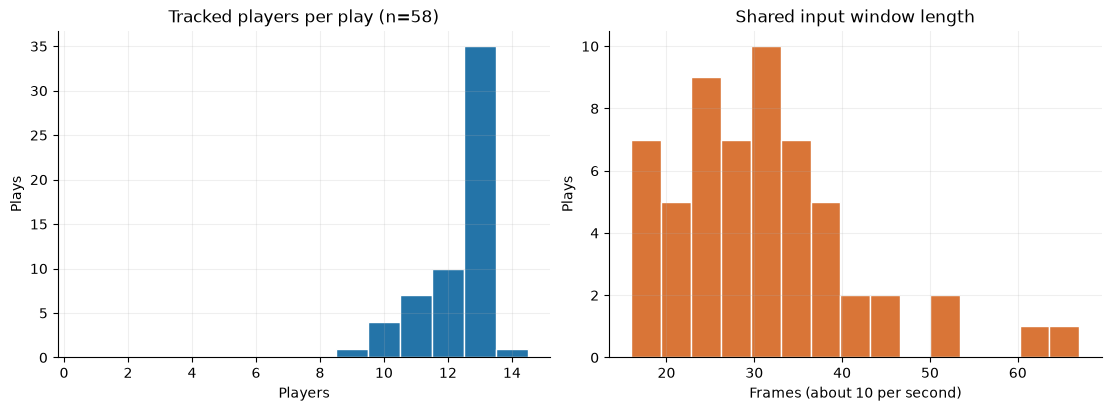

,players,input_frames,output_frames
count,58.0,58.0,58.0
mean,12.3,30.7,10.5
std,1.1,10.4,4.5
min,9.0,16.0,6.0
25%,12.0,24.2,7.0
50%,13.0,30.0,8.5
75%,13.0,34.0,12.0
max,14.0,67.0,23.0


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].hist(play_summary.players, bins=np.arange(0.5, play_summary.players.max()+1.5), color="#2474A8", edgecolor="white")
axes[0].set(title=f"Tracked players per play (n={len(play_summary)})", xlabel="Players", ylabel="Plays")
axes[1].hist(play_summary.input_frames, bins=15, color="#D97537", edgecolor="white")
axes[1].set(title="Shared input window length", xlabel="Frames (about 10 per second)", ylabel="Plays")
plt.show()
display(play_summary[["players", "input_frames", "output_frames"]].describe().round(1))

### 6. What roles are tracked, and how fast do they move?

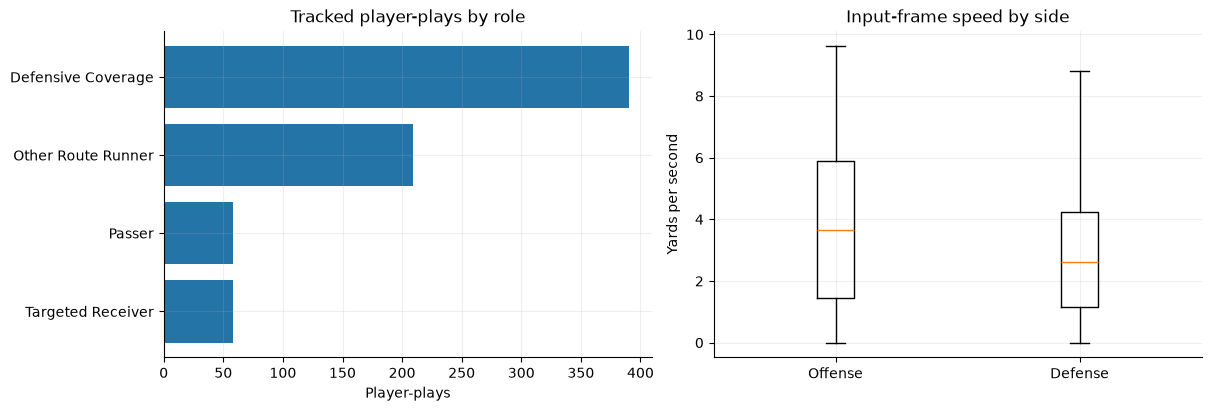

,count,median,mean,max
player_side,,,,
Defense,11999,2.63,2.81,9.17
Offense,9954,3.64,3.72,9.64


Speed summaries are at player-frame grain; repeated frames of one player are not independent observations.


In [6]:
input_rows = tracking.loc[tracking.segment.eq("input")].copy()
role_counts = player_play.player_role.value_counts().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].barh(role_counts.index, role_counts.values, color="#2474A8")
axes[0].set(title="Tracked player-plays by role", xlabel="Player-plays", ylabel="")
speed_groups = [
    input_rows.loc[input_rows.player_side.eq(side), "s"].dropna()
    for side in ["Offense", "Defense"]
]
axes[1].boxplot(speed_groups, tick_labels=["Offense", "Defense"], showfliers=False)
axes[1].set(title="Input-frame speed by side", ylabel="Yards per second")
plt.show()
display(input_rows.groupby("player_side").s.agg(["count", "median", "mean", "max"]).round(2))
print("Speed summaries are at player-frame grain; repeated frames of one player are not independent observations.")

### 7. Inspect one observed play trajectory

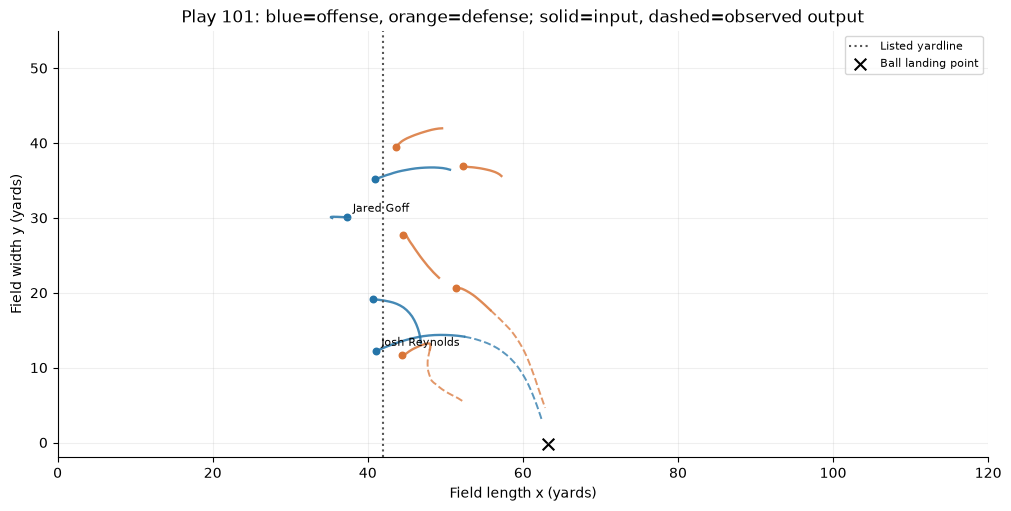

Play 101: 9 tracked players, 26 input frames, 21 output frames


In [7]:
sample = tracking.loc[tracking.play_id.eq(101)].sort_values(["nfl_id", "frame_id"])
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
colors = {"Offense": "#2474A8", "Defense": "#D97537"}
for player_id, group in sample.groupby("nfl_id"):
    before = group.loc[group.segment.eq("input")]
    after = group.loc[group.segment.eq("output")]
    color = colors[group.player_side.iloc[0]]
    ax.plot(before.x, before.y, color=color, lw=1.7, alpha=0.85)
    ax.scatter(before.x.iloc[0], before.y.iloc[0], color=color, s=22)
    if not after.empty:
        ax.plot(pd.concat([before.x.tail(1), after.x]), pd.concat([before.y.tail(1), after.y]),
                color=color, lw=1.4, ls="--", alpha=0.75)
    if group.player_role.iloc[0] in ["Passer", "Targeted Receiver"]:
        ax.annotate(group.player_name.iloc[0], (before.x.iloc[0], before.y.iloc[0]), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.axvline(sample.absolute_yardline_number.iloc[0], color="#555555", ls=":", label="Listed yardline")
ax.scatter(sample.ball_land_x.iloc[0], sample.ball_land_y.iloc[0], marker="x", s=70, color="black", label="Ball landing point")
ax.set(xlim=(0, 120), ylim=(-2, 55), xlabel="Field length x (yards)", ylabel="Field width y (yards)",
       title="Play 101: blue=offense, orange=defense; solid=input, dashed=observed output")
ax.legend(loc="upper right", fontsize=8)
plt.show()
print(f"Play 101: {sample.nfl_id.nunique()} tracked players, {int(play_summary.loc[101, 'input_frames'])} input frames, {int(play_summary.loc[101, 'output_frames'])} output frames")

## Takeaways

- The file is a **selected-player tracking extract** for 58 pass plays, with one row per game, play, player, and frame. It does not represent complete 22-player coverage.
- The shared input and selected output windows must be analyzed separately. Speed, acceleration, and angles are missing on appended output rows; that missingness is structural.
- The plots describe observed movement. The file has no explicit snap, throw, catch, outcome, or official route labels, so this first pass does not rate route quality or pass effectiveness.
- Next Phase 1 step: document the few coordinate or coverage exceptions and select representative plays for direction-normalized plotting.